# Figure 2b. Number of independent QTL

Number of independent QTL (95% credible/colocalized sets) found by *cis*-eGene fine-mapping and by the three TransMap modules, split by how many target genes or programs each QTL is linked to. Thresholds: P < 5e-8 for *cis*-eGene and TransMap-eGene, P < 5e-7 for TransMap-local and TransMap-global.

Input: `data/Figure_2b_independent_qtl.rds`.

In [1]:
library(ggplot2)
library(ggtext)
res <- readRDS("data/Figure_2b_independent_qtl.rds")
aggregate(n_loci ~ method, data = res, FUN = sum)

method,n_loci
<fct>,<int>
cis-eGene,21642
TransMap-eGene,17054
TransMap-local,21315
TransMap-global,4507


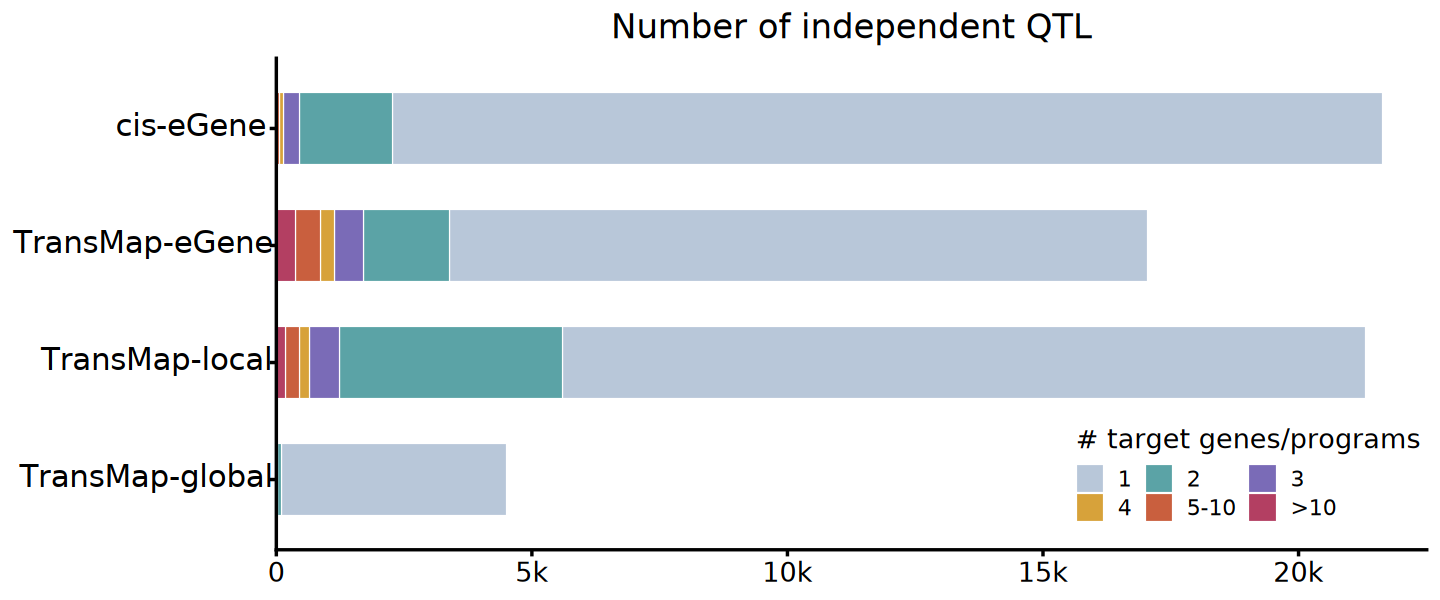

In [2]:
pal <- c("1" = "#B8C7D9", "2" = "#5BA3A6", "3" = "#7A6BB7",
         "4" = "#D7A23A", "5-10" = "#C95F3E", ">10" = "#B33F62")
method_labels <- c("cis-eGene" = "*cis*-eGene", "TransMap-eGene" = "TransMap-eGene",
                   "TransMap-local" = "TransMap-local", "TransMap-global" = "TransMap-global")
res$method <- factor(res$method, levels = rev(levels(res$method)))

p <- ggplot(res, aes(x = n_loci, y = method, fill = target_bin)) +
  geom_col(width = 0.62, colour = "white", linewidth = 0.25) +
  scale_fill_manual(values = pal, drop = FALSE) +
  scale_x_continuous(labels = function(x) ifelse(x == 0, "0", paste0(x / 1000, "k")),
                     expand = expansion(mult = c(0, 0.04))) +
  scale_y_discrete(labels = method_labels) +
  labs(title = "Number of independent QTL", x = NULL, y = NULL,
       fill = "# target genes/programs") +
  theme_classic(base_size = 16) +
  theme(plot.title = element_text(size = 20, hjust = 0.5),
        axis.text.y = element_markdown(size = 18),
        axis.text.x = element_text(size = 16),
        legend.position = "inside", legend.position.inside = c(1, 0.03),
        legend.justification = c(1, 0)) +
  guides(fill = guide_legend(title.position = "top", nrow = 2, byrow = TRUE))

options(repr.plot.width = 12, repr.plot.height = 5)
p